# Lab 01 · 추천 시스템 기본기: 인기도 → 아이템 기반 CF → 행렬 분해(BPR)

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 절 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| 1 | 암묵적 피드백 데이터와 leave-one-out 평가, Recall@K·NDCG@K | *Collaborative Filtering for Implicit Feedback Datasets* (2008) |
| 2 | 가장 단순한 기준선: 인기도 | Dacrema et al. (2019) *Are We Really Making Much Progress?* |
| 3 | "이 상품을 본 사람이 함께 본 상품" | Linden et al. (2003) *Amazon item-to-item CF* |
| 4 | 사용자·아이템을 벡터로: 행렬 분해와 BPR 손실 | Koren et al. (2009) *Matrix Factorization*, Rendle et al. (2009) *BPR* |
| 5 | 정확도 말고 볼 것: 인기 편향과 커버리지 | Netflix (2015), YouTube (2016) |

**소요 시간**: 60~90분 · **패키지**: numpy, pandas, matplotlib, torch (CPU 1분 이내)

> 데이터는 직접 만든 **합성 데이터**입니다(사용자 취향 벡터 + 아이템 인기도로 클릭을 생성). 정답 구조를 알고 있어서 방법들이 무엇을 잡아내는지 해석하기 좋습니다. 실제 데이터로 넘어갈 때는 MovieLens(GroupLens 제공)를 같은 코드에 넣어 보세요.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn, torch.nn.functional as F
rng = np.random.default_rng(0); torch.manual_seed(0)
plt.rcParams.update({"figure.figsize": (7, 3.2), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

## 1. 데이터와 평가 방법

추천 데이터는 대부분 별점이 아니라 **클릭·시청·구매 기록**(암묵적 피드백)입니다. "봤다(1)"는 있지만 "싫어한다"는 신호는 없습니다. 안 본 것은 싫어서일 수도, 몰라서일 수도 있습니다.

데이터 생성 규칙: 사용자 $u$ 가 아이템 $i$ 를 고를 가능성 ∝ exp(취향 일치도 + 아이템 인기도).

평가는 **leave-one-out**: 사용자마다 마지막 상호작용 1개를 숨기고, 나머지로 학습해 "숨긴 아이템을 상위 K개 안에 추천했는가"를 봅니다.

사용자 1000명, 아이템 500개, 학습 상호작용 36,428건, 채워진 비율 7.3%
상위 10% 아이템이 전체 상호작용의 30% 를 차지 (롱테일)


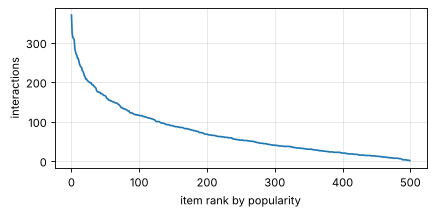

In [2]:
n_users, n_items, dim_true = 1000, 500, 8
user_taste = rng.normal(0, 1, (n_users, dim_true)); item_attr = rng.normal(0, 1, (n_items, dim_true))
item_pop = rng.normal(0, 1.2, n_items)                                   # 아이템 고유의 인기도(로그 스케일)
logits = 0.7 * user_taste @ item_attr.T + item_pop[None, :]

train_rows, test_item = [], np.zeros(n_users, dtype=int)
for u in range(n_users):
    p = np.exp(logits[u] - logits[u].max()); p /= p.sum()
    items = rng.permutation(rng.choice(n_items, size=rng.integers(15, 60), replace=False, p=p))   # 이 순서를 시간 순서로 본다
    test_item[u] = items[-1]                                              # 마지막 1개는 평가용으로 숨김
    train_rows += [(u, i) for i in items[:-1]]
train = np.array(train_rows)
R = np.zeros((n_users, n_items), dtype=np.float32); R[train[:, 0], train[:, 1]] = 1   # 사용자 x 아이템 행렬 (학습용)

counts = R.sum(axis=0)
print(f"사용자 {n_users}명, 아이템 {n_items}개, 학습 상호작용 {len(train):,}건, 채워진 비율 {R.mean():.1%}")
print(f"상위 10% 아이템이 전체 상호작용의 {np.sort(counts)[::-1][:n_items // 10].sum() / counts.sum():.0%} 를 차지 (롱테일)")
plt.figure(figsize=(6, 2.6)); plt.plot(np.sort(counts)[::-1]); plt.xlabel("item rank by popularity"); plt.ylabel("interactions"); plt.show()

In [3]:
def evaluate(scores, k=10):
    """scores: (사용자 수, 아이템 수). 이미 본 아이템은 추천에서 제외하고, 숨긴 아이템의 순위로 지표 계산"""
    s = np.where(R > 0, -np.inf, scores)
    target = s[np.arange(n_users), test_item]
    rank = (s > target[:, None]).sum(axis=1) + 1                          # 숨긴 아이템보다 점수가 높은 아이템 수 + 1
    hit = rank <= k
    topk = np.argsort(-s, axis=1)[:, :k]
    return {"Recall@10": hit.mean(), "NDCG@10": np.where(hit, 1 / np.log2(rank + 1), 0).mean(),
            "coverage": len(np.unique(topk)) / n_items, "avg_pop_rank": np.mean(pop_rank[topk])}, topk

pop_rank = np.argsort(np.argsort(-counts))                                # 0 = 가장 인기 있는 아이템
results = {}

- **Recall@10**: 숨긴 아이템이 상위 10개 안에 있는 사용자의 비율 (leave-one-out에서는 HitRate와 같음)
- **NDCG@10**: 맞혔더라도 **얼마나 위에** 두었는지 반영 (1위면 1, 아래로 갈수록 로그로 감소)
- **coverage**: 한 번이라도 추천된 아이템의 비율 · **avg_pop_rank**: 추천된 아이템의 평균 인기 순위(작을수록 인기 상품 위주)

## 2. 기준선: 모두에게 인기 상품 추천

✍️ **예측**: 개인화가 전혀 없는 인기도 추천의 Recall@10은 얼마쯤일까요? (무작위 추천이면 10/500 = 0.02)

In [4]:
results["popularity"], _ = evaluate(np.tile(counts, (n_users, 1)))
results["random"], _ = evaluate(rng.random((n_users, n_items)))
pd.DataFrame(results).T.round(3)

,Recall@10,NDCG@10,coverage,avg_pop_rank
popularity,0.122,0.064,0.052,6.931
random,0.024,0.011,1.000,259.248


인기도 추천은 무작위보다 **몇 배** 좋습니다. 사람들은 실제로 인기 있는 것을 많이 보기 때문입니다. 새 모델이 "인기도보다 얼마나 나은가"를 보이지 않으면 아무것도 보인 것이 아닙니다.

## 3. 아이템 기반 협업 필터링 (Linden et al., 2003)

"이 아이템을 본 사람들이 함께 본 아이템"이 비슷한 아이템입니다. 아이템 벡터(누가 봤는지)의 코사인 유사도를 구하고, 사용자가 본 아이템들과 유사한 아이템에 점수를 줍니다. 학습이 필요 없고, 추천 이유를 설명하기 쉽습니다.

In [5]:
norms = np.linalg.norm(R, axis=0, keepdims=True) + 1e-9
item_sim = (R.T @ R) / (norms.T @ norms)                                  # (아이템, 아이템) 코사인 유사도
np.fill_diagonal(item_sim, 0)
def keep_top_neighbors(S, n=50):                                          # 아이템마다 가장 비슷한 n개만 남긴다 (잡음 제거)
    cut = np.sort(S, axis=1)[:, -n][:, None]
    return np.where(S >= cut, S, 0)
results["item-kNN"], topk_knn = evaluate(R @ keep_top_neighbors(item_sim))
pd.DataFrame(results).T.round(3)

,Recall@10,NDCG@10,coverage,avg_pop_rank
popularity,0.122,0.064,0.052,6.931
random,0.024,0.011,1.000,259.248
item-kNN,0.332,0.197,0.316,27.031


## 4. 행렬 분해와 BPR (Koren et al., 2009; Rendle et al., 2009)

사용자와 아이템을 같은 공간의 벡터 $p_u, q_i$ 로 나타내고 점수를 내적 $\hat x_{ui}=p_u^\top q_i$ 로 정합니다. 암묵적 피드백에는 정답 점수가 없으므로 BPR은 **순서**를 학습합니다.

> 사용자가 본 아이템 $i$ 의 점수가, 안 본 아이템 $j$ 의 점수보다 높아야 한다.

$$L_{BPR}=-\sum_{(u,i,j)}\ln\sigma(\hat x_{ui}-\hat x_{uj})+\lambda\lVert\Theta\rVert^2$$

✍️ **예측**: 안 본 아이템 $j$ 를 무작위로 뽑으면 가끔 "사실은 좋아할" 아이템이 음성으로 뽑힙니다. 그래도 학습이 될까요?

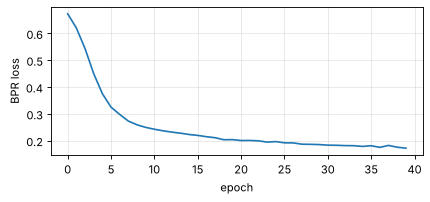

,Recall@10,NDCG@10,coverage,avg_pop_rank
popularity,0.122,0.064,0.052,6.931
random,0.024,0.011,1.000,259.248
item-kNN,0.332,0.197,0.316,27.031
BPR-MF,0.319,0.192,0.846,113.265


In [6]:
class MF(nn.Module):
    def __init__(self, n_users, n_items, dim=32):
        super().__init__()
        self.P = nn.Embedding(n_users, dim); self.Q = nn.Embedding(n_items, dim); self.item_bias = nn.Embedding(n_items, 1)
        nn.init.normal_(self.P.weight, std=0.05); nn.init.normal_(self.Q.weight, std=0.05); nn.init.zeros_(self.item_bias.weight)
    def score(self, u, i): return (self.P(u) * self.Q(i)).sum(-1) + self.item_bias(i).squeeze(-1)
    def all_scores(self): return (self.P.weight @ self.Q.weight.T + self.item_bias.weight.T).detach().numpy()

def train_bpr(dim=32, epochs=40, lr=0.01, weight_decay=1e-5, seed=0):
    torch.manual_seed(seed); model = MF(n_users, n_items, dim)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    u_all, i_all = torch.tensor(train[:, 0]), torch.tensor(train[:, 1]); history = []
    for _ in range(epochs):
        perm = torch.randperm(len(u_all)); total = 0.0
        for b in range(0, len(perm), 2048):
            idx = perm[b:b + 2048]; u, i = u_all[idx], i_all[idx]
            j = torch.randint(0, n_items, (len(idx),))                    # 음성 아이템을 무작위로
            loss = -F.logsigmoid(model.score(u, i) - model.score(u, j)).mean()
            opt.zero_grad(); loss.backward(); opt.step(); total += loss.item() * len(idx)
        history.append(total / len(perm))
    return model, history

bpr, hist = train_bpr()
results["BPR-MF"], topk_bpr = evaluate(bpr.all_scores())
plt.figure(figsize=(6, 2.4)); plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("BPR loss"); plt.show()
pd.DataFrame(results).T.round(3)

표를 읽는 법
- 개인화 모델(item-kNN, BPR-MF)이 인기도보다 얼마나 나은지, 두 모델끼리의 차이는 얼마나 되는지 보세요. **학습이 필요 없는 item-kNN이 신경망·행렬 분해와 큰 차이가 없거나 더 나은 경우**는 실제 논문 재현에서도 반복해서 보고됩니다 (Dacrema et al., 2019; Rendle et al., 2020). 새 모델을 평가할 때 잘 튜닝한 단순 기준선이 꼭 필요한 이유입니다.
- 사용자 1,000명 평가에서 Recall 0.01 차이는 **10명 차이**입니다. 시드를 바꿔 여러 번 돌려 보기 전에는 순위를 단정하지 마세요.

## 5. 정확도만 보면 놓치는 것: 인기 편향과 커버리지

위 표의 `coverage`, `avg_pop_rank` 열을 보세요.

✍️ **예측**: 인기도 추천의 coverage는 얼마일까요? Recall이 비슷한 두 개인화 모델은 추천하는 아이템의 폭도 비슷할까요?

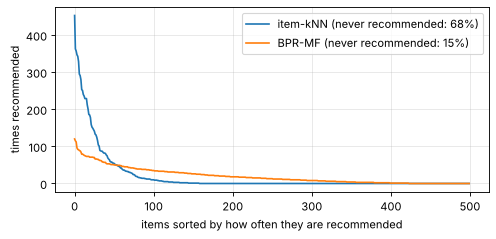

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
for name, topk in {"item-kNN": topk_knn, "BPR-MF": topk_bpr}.items():
    rec_counts = np.bincount(topk.ravel(), minlength=n_items)
    ax.plot(np.sort(rec_counts)[::-1], label=f"{name} (never recommended: {np.mean(rec_counts == 0):.0%})")
ax.set_xlabel("items sorted by how often they are recommended"); ax.set_ylabel("times recommended"); ax.legend(); plt.show()

- 인기도 추천은 모든 사용자에게 거의 같은 수십 개만 보여 줍니다(coverage 약 5%).
- item-kNN과 BPR-MF는 Recall@10이 비슷한데도 **추천 목록의 성격이 전혀 다릅니다.** 이 실행에서 item-kNN은 전체 아이템의 약 1/3만 추천하고 인기 상품 쪽으로 쏠리며, BPR-MF는 훨씬 넓게 추천합니다. 정확도 지표 하나로는 이 차이가 보이지 않습니다.
- 추천은 데이터 수집에도 영향을 줍니다. 노출된 것만 클릭될 수 있으므로, 쏠린 추천은 쏠린 로그를 만들고 그 로그로 다시 학습합니다(피드백 루프).
- 그래서 산업 논문들은 오프라인 정확도 외에 다양성·신선도·장기 만족도를 함께 보고, 최종 판단은 **온라인 A/B 테스트**로 합니다(Netflix 2015, YouTube 2016). 오프라인 지표가 올랐는데 온라인 성과가 그대로인 일은 흔합니다.

---
## 직접 해보기

1. **(임베딩 차원)** BPR-MF의 `dim` 을 4, 16, 64로 바꿔 Recall@10을 비교하세요. 데이터를 만든 참 차원(8)과 어떤 관계가 보이나요?
2. **(새 사용자)** 아이템 3개만 본 새 사용자가 있습니다. 재학습 없이 (a) item-kNN과 (b) BPR-MF의 아이템 임베딩 평균을 사용자 벡터로 써서 각각 상위 5개를 추천해 보세요.
3. **(지표의 K)** `evaluate` 를 고쳐 K=1, 5, 20, 50의 Recall을 구하고, K에 따라 모델 순위가 바뀌는지 확인하세요.

In [8]:
# TODO 1: dim 바꿔 보기

# TODO 2: 새 사용자에게 추천

# TODO 3: 여러 K

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [9]:
# 1. 임베딩 차원
for dim in [4, 16, 64]:
    m, _ = train_bpr(dim=dim)
    print(f"dim={dim:2d}: Recall@10 = {evaluate(m.all_scores())[0]['Recall@10']:.3f}")

dim= 4: Recall@10 = 0.245


dim=16: Recall@10 = 0.350


dim=64: Recall@10 = 0.294


In [10]:
# 2. 새 사용자: 본 아이템 3개
seen = [int(np.argsort(-counts)[20]), int(np.argsort(-counts)[150]), int(np.argsort(-counts)[300])]
knn_scores = keep_top_neighbors(item_sim)[seen].sum(axis=0); knn_scores[seen] = -np.inf
Q = bpr.Q.weight.detach().numpy(); bias = bpr.item_bias.weight.detach().numpy()[:, 0]
mf_scores = Q @ Q[seen].mean(axis=0) + bias; mf_scores[seen] = -np.inf
print("본 아이템:", seen)
print("item-kNN 추천:", np.argsort(-knn_scores)[:5].tolist())
print("MF(아이템 임베딩 평균) 추천:", np.argsort(-mf_scores)[:5].tolist())

본 아이템: [70, 255, 261]
item-kNN 추천: [106, 124, 485, 412, 453]
MF(아이템 임베딩 평균) 추천: [308, 495, 440, 390, 84]


In [11]:
# 3. 여러 K 에서의 Recall
def recall_at(scores, ks=(1, 5, 20, 50)):
    s = np.where(R > 0, -np.inf, scores); target = s[np.arange(n_users), test_item]
    rank = (s > target[:, None]).sum(axis=1) + 1
    return {f"Recall@{k}": (rank <= k).mean() for k in ks}
pd.DataFrame({"popularity": recall_at(np.tile(counts, (n_users, 1))), "item-kNN": recall_at(R @ keep_top_neighbors(item_sim)), "BPR-MF": recall_at(bpr.all_scores())}).T.round(3)

,Recall@1,Recall@5,Recall@20,Recall@50
popularity,0.023,0.083,0.201,0.361
item-kNN,0.094,0.236,0.432,0.591
BPR-MF,0.095,0.221,0.451,0.628


**해석**
- 1번: 차원이 너무 작으면 취향을 다 담지 못하고, 너무 크면 이 정도 데이터에서는 이득이 줄거나 과적합합니다. 하이퍼파라미터에 따라 "어느 모델이 이기는가"가 바뀔 수 있다는 점이 재현성 논문들의 핵심 지적입니다.
- 2번: 새 사용자의 벡터를 "본 아이템 임베딩의 평균"으로 만드는 것은 투타워·시퀀스 모델의 가장 단순한 형태입니다. YouTube 논문의 후보 생성 모델이 시청 기록 임베딩을 평균해 사용자 벡터를 만드는 것과 같은 발상입니다.

---
## 논문으로 돌아가기

| 방금 한 것 | 논문에서 확인할 곳 |
|---|---|
| 3절 | Amazon (2003): 사용자 기반이 아니라 **아이템 기반**을 택한 이유(규모, 오프라인 사전 계산) |
| 4절 | Koren (2009): 편향 항(bias)·암묵적 피드백·시간 변화를 추가해 가는 과정. BPR (2009): 손실의 유도와 "학습 알고리즘(LearnBPR)" |
| 2·4절 표 | Dacrema (2019): 재현 대상 논문 중 몇 편이 재현됐고, 그중 몇 편이 단순 기준선을 이겼는지 |
| 5절 | YouTube (2016): 오프라인 지표와 A/B 테스트의 관계에 대한 언급, "시청 시간"을 목표로 삼은 이유 |

## 기억 점검

1. 암묵적 피드백이 별점 데이터와 다른 점은?
2. Recall@K와 NDCG@K의 차이는?
3. item-kNN의 점수는 어떻게 계산되나? 장점 두 가지는?
4. BPR 손실이 최적화하는 것은 무엇인가? 음성 샘플은 어떻게 얻나?
5. 오프라인 Recall이 오른 모델이 온라인 A/B 테스트에서 지는 이유가 될 만한 것 두 가지는?

<details><summary>답 확인</summary>

1. "봤다"만 있고 "싫다"가 없다. 관측되지 않은 것은 부정이 아니라 미지(몰라서 안 봤을 수 있음)다.
2. Recall@K는 상위 K 안에 있는지만, NDCG@K는 그 안에서의 순위(위일수록 큰 점수)까지 반영한다.
3. 사용자가 본 아이템들과 후보 아이템의 유사도 합. 학습이 필요 없고(계산만), 추천 이유("이것을 봤기 때문에")를 설명하기 쉽다.
4. 본 아이템이 안 본 아이템보다 점수가 높도록 하는 **쌍 단위 순서**. 음성은 사용자가 보지 않은 아이템 중에서 샘플링한다.
5. 오프라인 데이터는 과거 추천 정책이 보여 준 것에 치우쳐 있다(노출 편향). 오프라인 지표(다음 클릭 맞히기)와 실제 목표(만족도, 장기 이용)가 다르다. 인기 쏠림·다양성 저하 등.
</details>